In [ ]:
# 合并BED文件
for f in *.narrowPeak; do
  cut -f1-6 "$f" > "${f%.narrowPeak}.bed"
done
cat *_peaks.bed | sort -k1,1 -k2,2n | bedtools merge -i - > merged.bed
awk 'BEGIN {OFS="\t"} {
    source = "BED";
    feature = "exon";
    score = ".";
    frame = ".";
    
    strand = ($6 != "") ? $6 : ".";
    
    start = $2 + 1;
    end = $3;
    
    peak_id = "peak_" NR;
    
    attributes = "gene_id \"" peak_id "\"; transcript_id \"" peak_id "\";";
    
    if ($4 != "") attributes = attributes " original_id \"" $4 "\";";
    
    print $1, source, feature, start, end, score, strand, frame, attributes;
}' merged.bed > merged.gtf


In [ ]:

awk 'BEGIN{OFS="\t"; print "GeneID","Chr","Start","End","Strand"} \
{
    print "peak_"NR, $1, $2+1, $3, "."
}' \
merged.bed \
> merged.saf


In [ ]:

#featureCounts -a merged.gtf -o chip_counts.txt -T 32 -p *.bam
featureCounts \
    -F SAF \
    -a merged.saf \
    -o chip-counts.txt \
    -T 32 \
    -p \
    --countReadPairs \
    *.bam


In [4]:
import matplotlib.pyplot as plt

# =========================
# 全局字体设置
# =========================
plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.sans-serif"] = ["Arial"]

# PDF 中保留文字为可编辑字体，而不是转成路径
plt.rcParams["pdf.fonttype"] = 42

# SVG 中保留文字为 text
plt.rcParams["svg.fonttype"] = "none"

# 避免负号显示问题
plt.rcParams["axes.unicode_minus"] = False

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

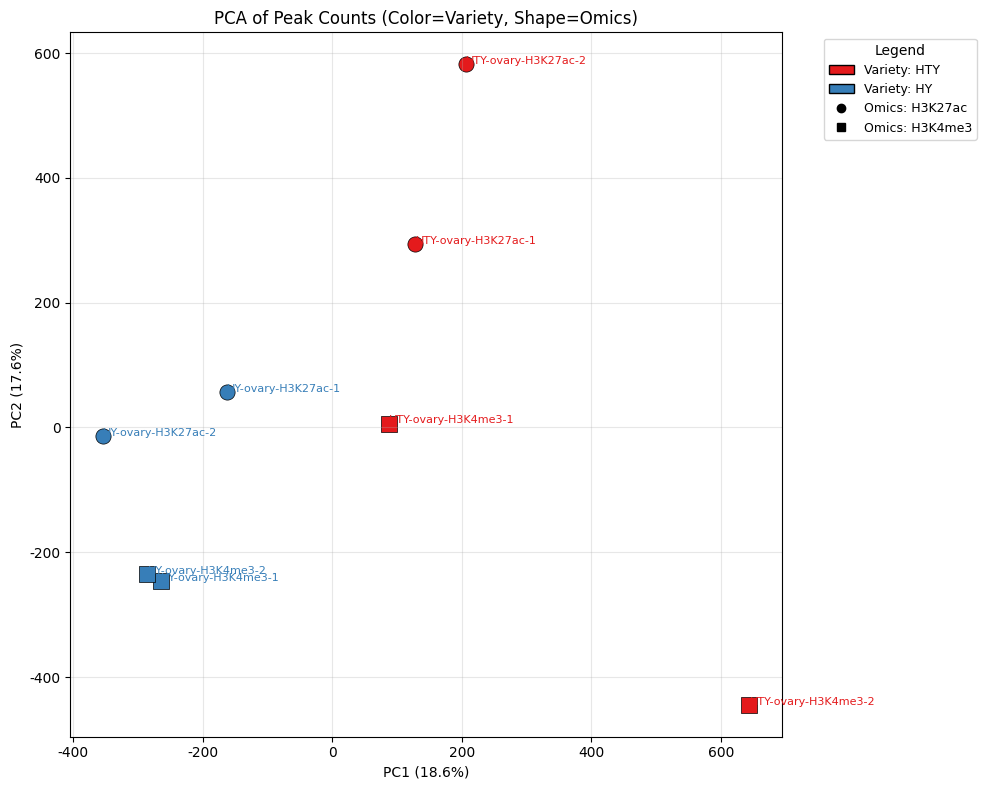

In [11]:
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.patches as mpatches
import matplotlib.lines as mlines

# 读取featureCounts结果
counts = pd.read_csv("/home/hnadmin/data/yangshuju/result/ovary/bam/chip_counts.txt", sep="\t", comment="#", header=0)
counts = counts.loc[:, ~counts.columns.str.contains("-merged.bam", case=False, na=False)]
counts = counts.loc[:, ~counts.columns.str.contains("-merged.sort.bam", case=False, na=False)]
sample_counts = counts.iloc[:, 6:]
samples = sample_counts.columns

# 清洗列名
clean_names = [
    path.replace('bam/', '').replace('.rmdup.bam', '').replace('.merge.sorted.bam', '').replace('-merge.sorted.bam', '').replace('.merge.sorted.bam', '')
    for path in samples
]
sample_counts.columns = clean_names

# 提取元信息
metadata = [name.split("-") for name in clean_names]
varieties = [m[0] for m in metadata]
tissues = [m[1] for m in metadata]
omics = [m[2] for m in metadata]

# 归一化 + log 转换
log_counts = np.log2(sample_counts.div(sample_counts.sum(axis=0), axis=1) * 1e6 + 1)
scaled_data = StandardScaler().fit_transform(log_counts.T)

# PCA
pca = PCA(n_components=2)
pca_result = pca.fit_transform(scaled_data)

# 整合信息
pca_df = pd.DataFrame({
    'PC1': pca_result[:, 0],
    'PC2': pca_result[:, 1],
    'Sample': clean_names,
    'Variety': varieties,
    'Tissue': tissues,
    'Omics': omics
})

# ✅ 颜色 → Variety（品种）
palette = sns.color_palette("Set1", len(set(varieties)))
variety_color = {v: c for v, c in zip(sorted(set(varieties)), palette)}

# ✅ 形状 → Omics（组学）
shapes = ['o', 's', '^', 'D', 'v', 'X', '*']
omics_marker = {o: shapes[i % len(shapes)] for i, o in enumerate(sorted(set(omics)))}

# 绘图
plt.figure(figsize=(10, 8))

for _, row in pca_df.iterrows():
    plt.scatter(
        row['PC1'], row['PC2'],
        color=variety_color[row['Variety']],
        marker=omics_marker[row['Omics']],
        edgecolor='black',
        s=120,
        linewidth=0.5
    )
    
    # ✅ 标签颜色也跟随品种（关键点）
    plt.text(
        row['PC1'] + 0.2,
        row['PC2'] + 0.2,
        row['Sample'],
        fontsize=8,
        color=variety_color[row['Variety']]
    )

# 构造图例
legend_elements = []

# Variety（颜色）
for v, c in variety_color.items():
    legend_elements.append(
        mpatches.Patch(facecolor=c, edgecolor='black', label=f"Variety: {v}")
    )

# Omics（形状）
for o, m in omics_marker.items():
    legend_elements.append(
        mlines.Line2D([], [], color='black', marker=m, linestyle='None', label=f"Omics: {o}")
    )

plt.legend(handles=legend_elements, bbox_to_anchor=(1.05, 1), loc='upper left', title="Legend", fontsize=9)

plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
plt.title("PCA of Peak Counts (Color=Variety, Shape=Omics)")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("pca_variety_color_omics_shape.pdf", dpi=300)
plt.show()

In [10]:
sample_counts

,HTY-ovary-H3K27ac-1,HTY-ovary-H3K27ac-2,HTY-ovary-H3K4me3-1,HTY-ovary-H3K4me3-2,HY-ovary-H3K27ac-1,HY-ovary-H3K27ac-2,HY-ovary-H3K4me3-1,HY-ovary-H3K4me3-2
0,1248,808,2018,1311,723,452,918,828
1,2018,1336,3331,2230,1261,957,1704,1592
2,786,518,1216,802,464,280,500,527
3,1119,767,1957,1101,706,465,828,819
4,1255,816,1986,1333,720,531,835,842
...,...,...,...,...,...,...,...,...
526248,18,24,19,14,12,15,8,17
526249,13,10,17,15,40,19,27,24
526250,8,5,7,14,17,2,8,18
526251,14,23,26,22,16,18,37,20


peak 数

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os 
os.chdir("/home/hnadmin/data/yangshuju/result/ovary/peak/")

files = [
    "HTY-ovary-H3K27ac-merged.bed",
    "HY-ovary-H3K27ac-merged.bed",
    "HTY-ovary-H3K4me3-merged.bed",
    "HY-ovary-H3K4me3-merged.bed"
]

data = []
for f in files:
    count = sum(1 for line in open(f) if not line.startswith("#"))
    parts = f.replace(".merged.bed", "").split("-")
    variety = parts[0]
    tissue = parts[1]
    omics = parts[2]
    
    data.append([variety, tissue, omics, count])

df = pd.DataFrame(data, columns=["Variety", "Tissue", "Omics", "PeakCount"])

In [4]:
df

,Variety,Tissue,Omics,PeakCount
0,HTY,ovary,H3K27ac,1
1,HY,ovary,H3K27ac,1
2,HTY,ovary,H3K4me3,1
3,HY,ovary,H3K4me3,1


In [11]:
df['PeakCount'] = [33,63,0,205]

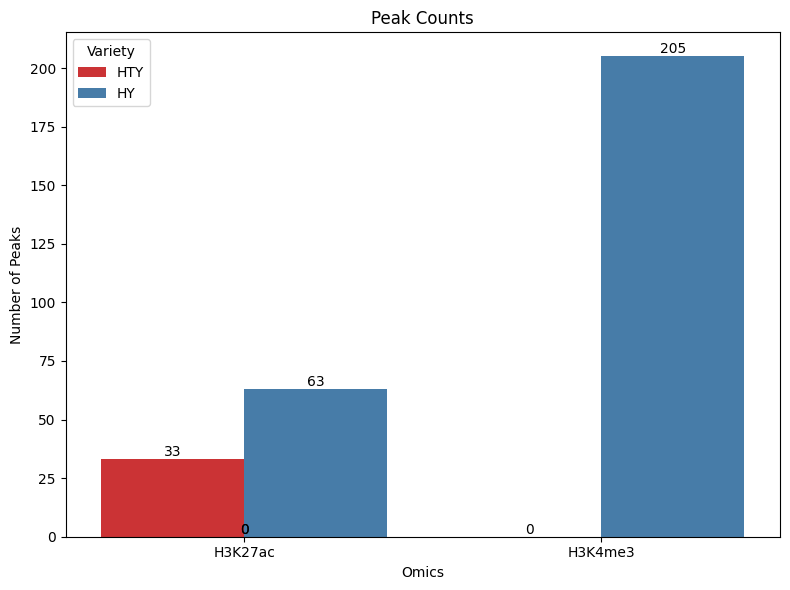

In [12]:
plt.figure(figsize=(8,6))

ax = sns.barplot(
    data=df,
    x="Omics",
    y="PeakCount",
    hue="Variety",
    palette=variety_color
)

# ✅ 在柱子上标数值
for p in ax.patches:
    height = p.get_height()
    ax.annotate(
        f'{int(height)}',
        (p.get_x() + p.get_width() / 2., height),
        ha='center',
        va='bottom',
        fontsize=10
    )

plt.title("Peak Counts")
plt.ylabel("Number of Peaks")
plt.xlabel("Omics")

plt.tight_layout()
#plt.savefig("peak_counts_barplot.pdf", dpi=300)
plt.savefig("/home/hnadmin/data/yangshuju/result/ovary/peak_target_gene_barplot.pdf",dpi=300)
plt.show()

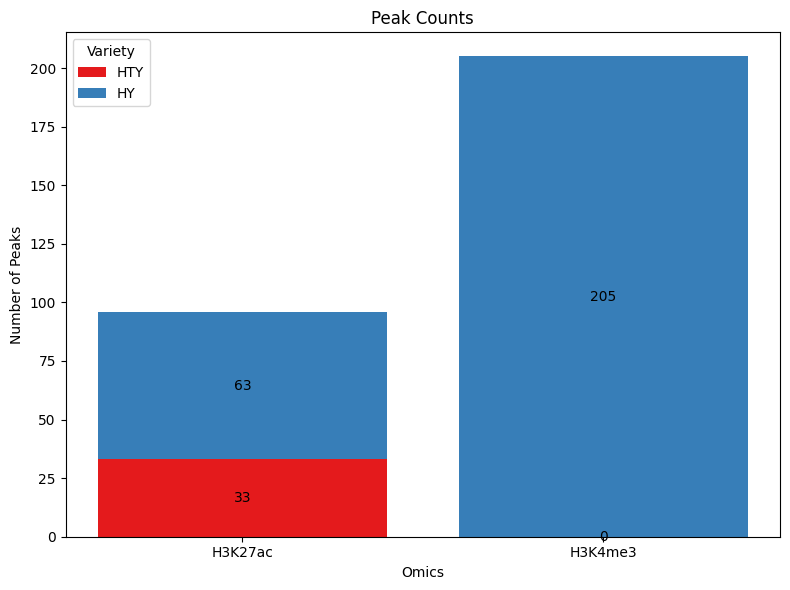

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

# 转换为宽表
pivot_df = df.pivot(
    index='Omics',
    columns='Variety',
    values='PeakCount'
)

fig, ax = plt.subplots(figsize=(8,6))

bottom = None

for variety in pivot_df.columns:
    ax.bar(
        pivot_df.index,
        pivot_df[variety],
        bottom=bottom,
        label=variety,
        color=variety_color[variety]
    )

    # 添加数字标签
    for i, v in enumerate(pivot_df[variety]):
        y_pos = v if bottom is None else bottom[i] + v

        ax.text(
            i,
            y_pos - v/2,  # 放在当前堆叠块中间
            f'{int(v)}',
            ha='center',
            va='center',
            fontsize=10
        )

    if bottom is None:
        bottom = pivot_df[variety].values.copy()
    else:
        bottom += pivot_df[variety].values

ax.set_title("Peak Counts")
ax.set_ylabel("Number of Peaks")
ax.set_xlabel("Omics")
ax.legend(title="Variety")

plt.tight_layout()

plt.savefig(
    "/home/hnadmin/data/yangshuju/result/ovary/peak_target_gene_barplot_stacked.pdf",
    dpi=300
)

plt.show()

In [3]:
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
os.chdir("/home/hnadmin/data/yangshuju/result/ovary/")
# 读取featureCounts结果
counts = pd.read_csv("/home/hnadmin/data/yangshuju/result/ovary/bam/chip_counts.txt", sep="\t", comment="#", header=0)
sample_counts = counts.iloc[:, 6:]
samples = sample_counts.columns

# 清洗列名
clean_names = [
    path.replace('bam/', '').replace('.rmdup.bam', '').replace('.merge.sorted.bam', '')
    for path in samples
]
sample_counts.columns = clean_names

# 提取元信息
metadata = [name.split("-") for name in clean_names]
varieties = [m[0] for m in metadata]
tissues = [m[1] for m in metadata]
omics = [m[2] for m in metadata]

# 归一化 + log 转换
log_counts = np.log2(sample_counts.div(sample_counts.sum(axis=0), axis=1) * 1e6 + 1)
scaled_data = StandardScaler().fit_transform(log_counts.T)

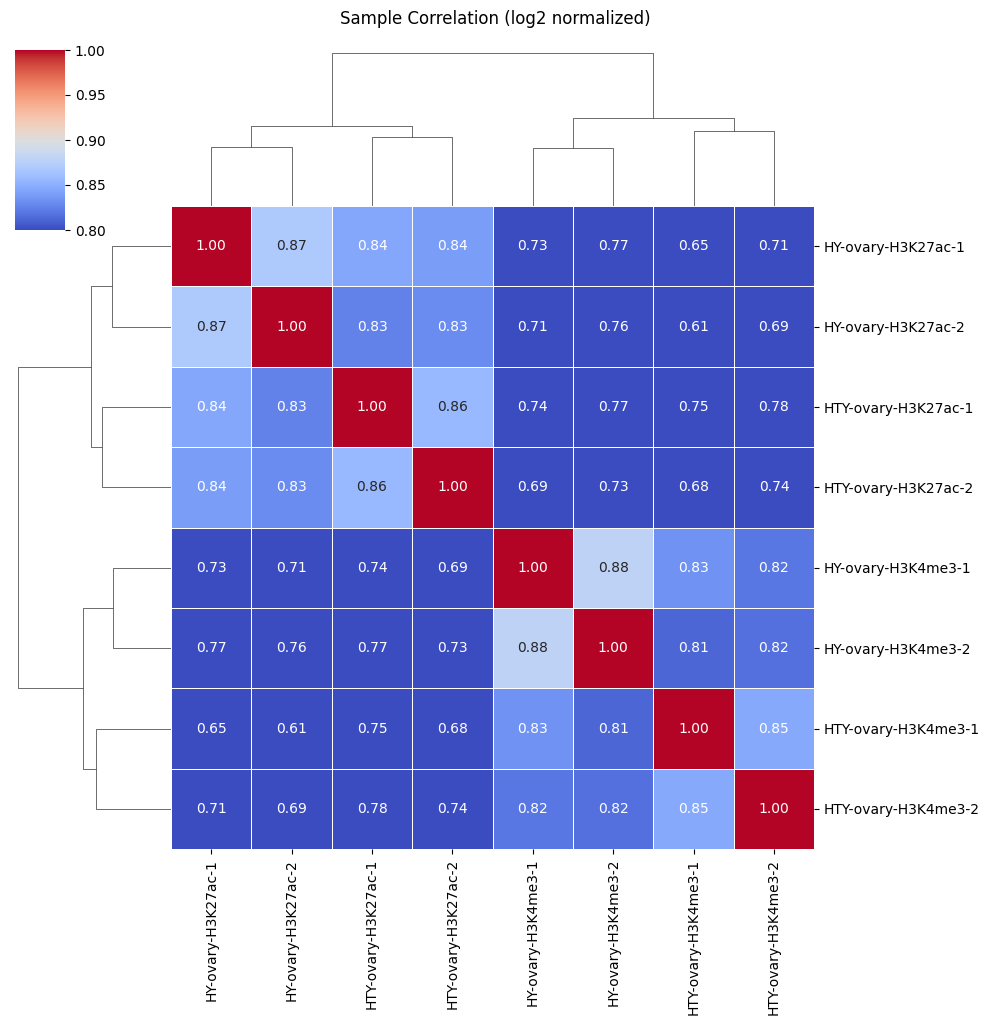

In [7]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# ===== 1. 过滤低信号（ChIP-seq建议保留有信号的peak）=====
df = sample_counts[sample_counts.sum(axis=1) > 10]

# ===== 2. log转换（避免极端值影响）=====
df_log = np.log2(df + 1)

# ===== 3. 计算相关性矩阵 =====
corr = df_log.corr(method='pearson')

# ===== 4. 绘制聚类热图 =====
sns.clustermap(
    corr,
    cmap='coolwarm',
    annot=True,
    fmt=".2f",
    figsize=(10, 10),
    vmin=0.8, vmax=1,
    linewidths=0.5
)

plt.suptitle("Sample Correlation (log2 normalized)", y=1.02)
plt.savefig("sample_correlation.pdf", dpi=300)
plt.show()

In [3]:
sample_counts

,HTY-ovary-H3K27ac-1,HTY-ovary-H3K27ac-2,HTY-ovary-H3K4me3-1,HTY-ovary-H3K4me3-2,HY-ovary-H3K27ac-1,HY-ovary-H3K27ac-2,HY-ovary-H3K4me3-1,HY-ovary-H3K4me3-2
0,1139,729,1827,1175,642,415,835,734
1,1968,1300,3247,2170,1230,929,1649,1549
2,705,473,1095,729,428,257,458,477
3,627,404,1160,577,395,260,462,475
4,1222,791,1914,1282,695,516,802,805
...,...,...,...,...,...,...,...,...
26223,37,45,45,37,48,48,42,47
26224,68,38,99,43,42,66,77,90
26225,29,34,54,28,68,46,84,102
26226,24,17,29,24,23,22,25,52
